# Language Modeling
Overview:
- Reading and explore dataset
- bigram: counting bigrams in dictionary and torch tensor, 
- spurious 'S' and 'E' tokens
- sampling from the model
- vectorized normalization of the rows, tensor broadcasting 
- model fake count
- Part 2: neural networks approach
    + Data loading: Bigram dataset for the neural net
    + Feature engineering: 
        + one hot encoding
        + Neural net: 
            + linear layer (matrix multiplication)
            + transforming NN -> probabilities (softmax)
    + Modeling:
        + Micrograd theory 
        + Vectorized loss -> loss computation
        + Backward and update
    + Putting everything together

Note:
- Bigrams:
    + vocabulary table: Counting -> probability 

In [3]:
import os
from pathlib import Path

## Data loading

In [ ]:

current_path = Path.cwd()
root_path = current_path.parents[2]
print(root_path)
data_path = str(root_path) + "/datasets/names/names.txt"
file = open(data_path, 'r', encoding='utf-8')
words = file.read().split('\n') # splitlines()
words[:10]

d:\University\Projects\Individual projects\Techstack-Training


['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [5]:
print(type(words))

<class 'list'>


In [6]:
print(min(len(w) for w in words))
print(max(len(w) for w in words))

2
15


# Feature engineering

In [32]:
b = {} # bigram counting table

for w in words:
    # print(type(w))
    chs = ['<S>'] + list(w) + ['<E>'] # transform the w to list 
    # print(chs)
    for ch1, ch2 in zip(chs, chs[1:]): # ch1[0] and ch1[1], ch1[1] and ch2[2], ...
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1
        # b[bigram] += 1

In [33]:
# Counting how often from ch1 and answer it with ch2
sorted(b.items(), key = lambda kv: -kv[1]) # kv[1] is the value (biến đếm tần suất) of counting table

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

## Torch tensor bigram

In [34]:
# library
import torch

In [35]:
"".join(words)

'...'

In [50]:
# matrix of vocabulary: N = (28, 28)
N = torch.zeros((28, 28), dtype=torch.int32)

In [51]:
# save char in N - encoding
chars = sorted(list(set(''.join(words))))
stoi = {s:i for i, s in enumerate(chars)} # note: index - char (example: 1 - A, 2 - B, ...)
stoi["<S>"] = 26
stoi["<E>"] = 27
stoi

{'a': 0,
 'b': 1,
 'c': 2,
 'd': 3,
 'e': 4,
 'f': 5,
 'g': 6,
 'h': 7,
 'i': 8,
 'j': 9,
 'k': 10,
 'l': 11,
 'm': 12,
 'n': 13,
 'o': 14,
 'p': 15,
 'q': 16,
 'r': 17,
 's': 18,
 't': 19,
 'u': 20,
 'v': 21,
 'w': 22,
 'x': 23,
 'y': 24,
 'z': 25,
 '<S>': 26,
 '<E>': 27}

In [52]:
# counting in words
for w in words:
    chs = ["<S>"] + list(w) + ['<E>']
    # print(chs)
    for ch1, ch2 in zip(chs, chs[1:]):
        # print(ch1, ch2)
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

In [53]:
N

tensor([[ 556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568, 2528,
         1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,  182,
         2050,  435,    0, 6640],
        [ 321,   38,    1,   65,  655,    0,    0,   41,  217,    1,    0,  103,
            0,    4,  105,    0,    0,  842,    8,    2,   45,    0,    0,    0,
           83,    0,    0,  114],
        [ 815,    0,   42,    1,  551,    0,    2,  664,  271,    3,  316,  116,
            0,    0,  380,    1,   11,   76,    5,   35,   35,    0,    0,    3,
          104,    4,    0,   97],
        [1303,    1,    3,  149, 1283,    5,   25,  118,  674,    9,    3,   60,
           30,   31,  378,    0,    1,  424,   29,    4,   92,   17,   23,    0,
          317,    1,    0,  516],
        [ 679,  121,  153,  384, 1271,   82,  125,  152,  818,   55,  178, 3248,
          769, 2675,  269,   83,   14, 1958,  861,  580,   69,  463,   50,  132,
         1070,  181,    0, 3983],
        [ 242,    0,

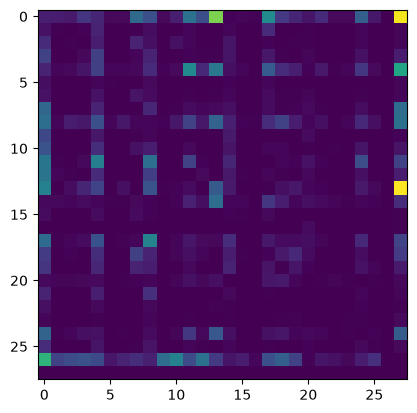

In [56]:
# Visualize the counting
import matplotlib.pyplot as plt
%matplotlib inline
plt.imshow(N)

In [69]:
# itos
itos = {i:s for i, s in enumerate(chars)}
itos[26] = '<S>'
itos[27] = '<E>'
itos

{0: 'a',
 1: 'b',
 2: 'c',
 3: 'd',
 4: 'e',
 5: 'f',
 6: 'g',
 7: 'h',
 8: 'i',
 9: 'j',
 10: 'k',
 11: 'l',
 12: 'm',
 13: 'n',
 14: 'o',
 15: 'p',
 16: 'q',
 17: 'r',
 18: 's',
 19: 't',
 20: 'u',
 21: 'v',
 22: 'w',
 23: 'x',
 24: 'y',
 25: 'z',
 26: '<S>',
 27: '<E>'}

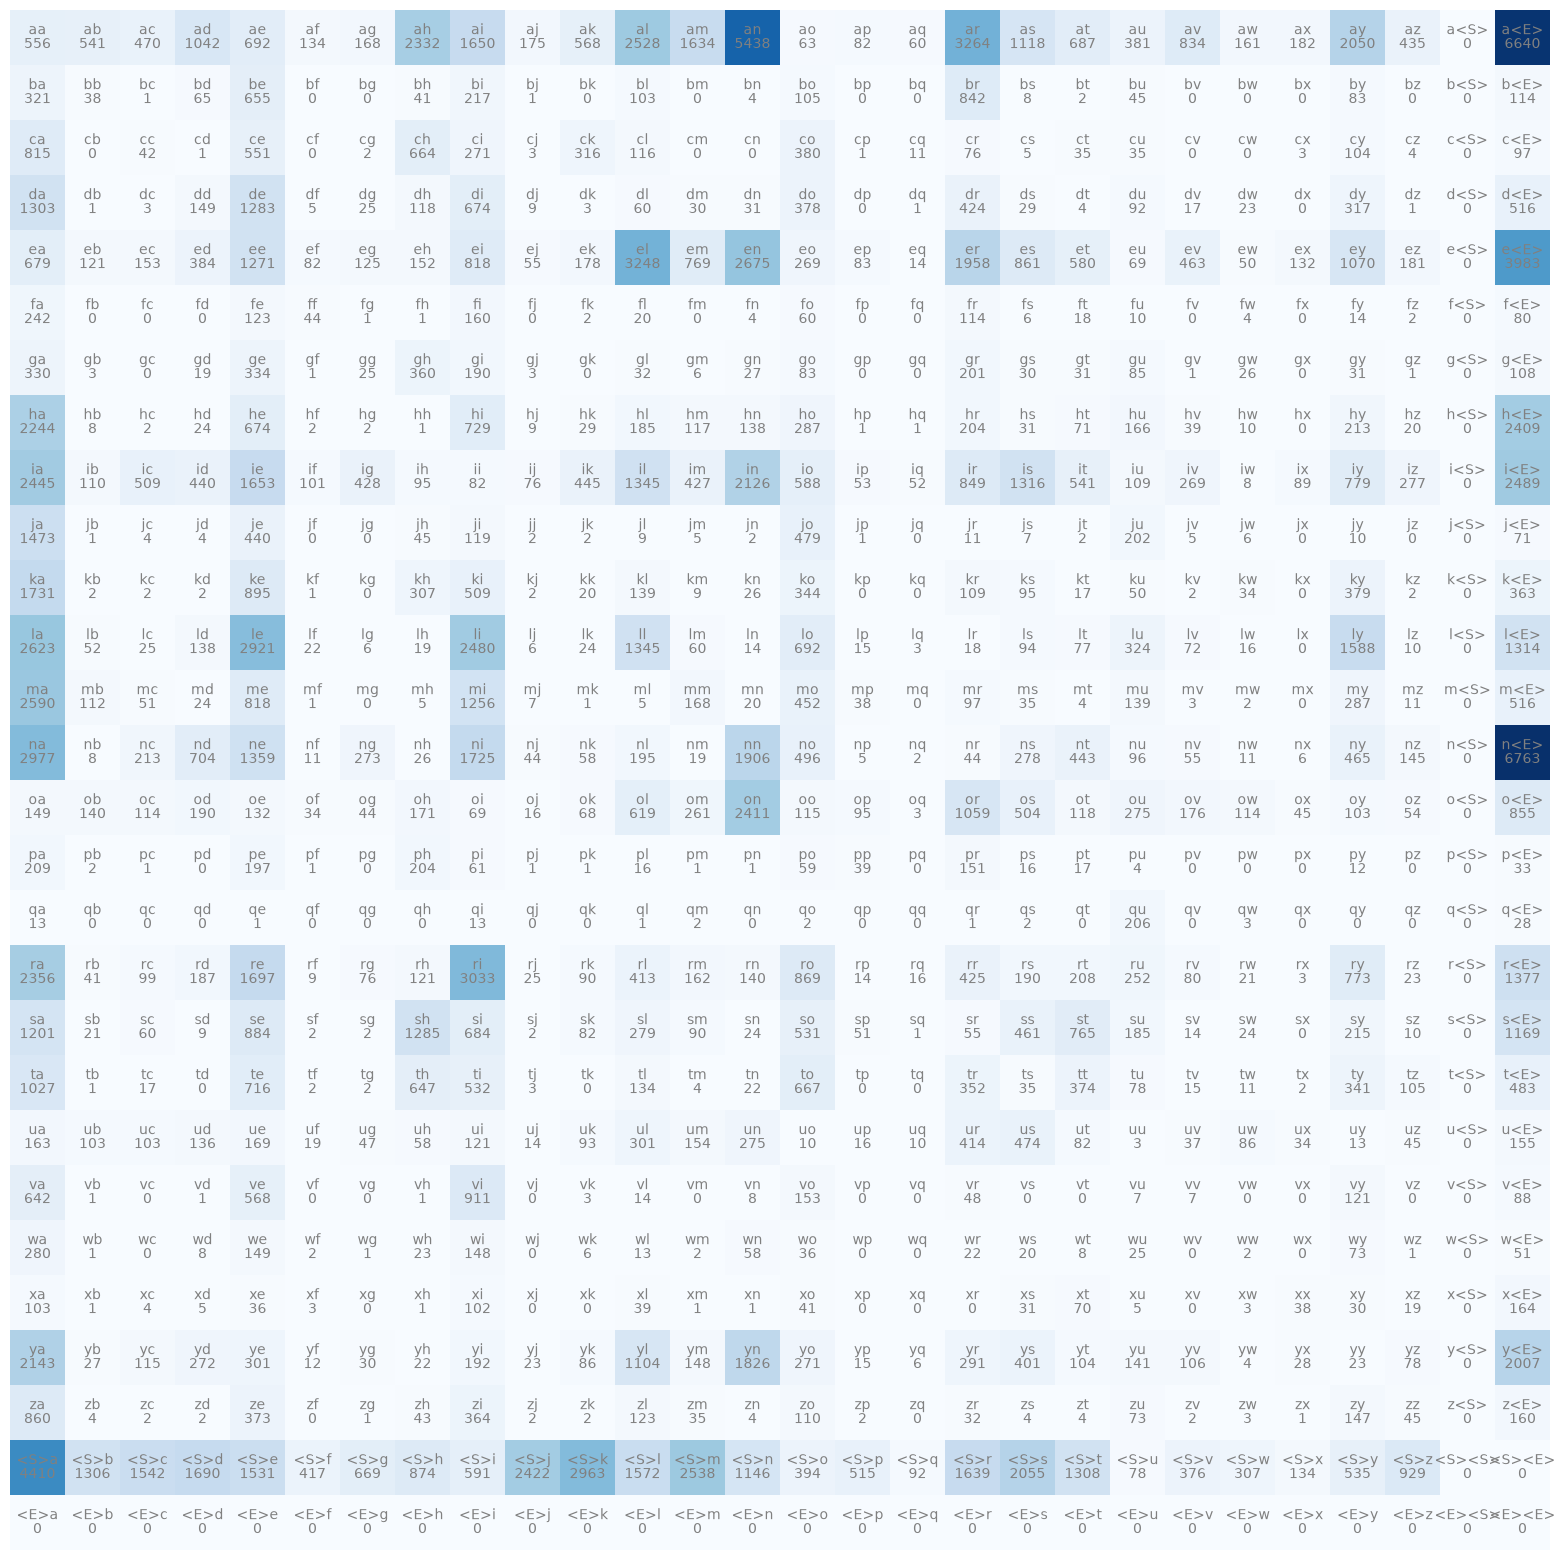

In [70]:
plt.figure(figsize=(20, 20))
plt.imshow(N, cmap="Blues")
for i in range(28):
    for j in range(28):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha='center', va='bottom', color='gray')
        plt.text(j, i, N[i, j].item(), ha='center', va='top', color='gray')
plt.axis('off')
plt.show()

## Sampling

In [72]:
N[0]

tensor([ 556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568, 2528,
        1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,  182,
        2050,  435,    0, 6640], dtype=torch.int32)

In [86]:
g = torch.Generator().manual_seed(42)
prob = torch.rand(3, generator=g)
prob = prob / prob.sum()
prob

tensor([0.4047, 0.4197, 0.1756])

In [110]:
g = torch.Generator().manual_seed(42)
p = N[0].float()
p = p / p.sum()
p

tensor([0.0164, 0.0160, 0.0139, 0.0308, 0.0204, 0.0040, 0.0050, 0.0688, 0.0487,
        0.0052, 0.0168, 0.0746, 0.0482, 0.1605, 0.0019, 0.0024, 0.0018, 0.0963,
        0.0330, 0.0203, 0.0112, 0.0246, 0.0048, 0.0054, 0.0605, 0.0128, 0.0000,
        0.1960])

In [111]:
# torch.multinomial() is used to sample indices based on weights/probabilities.
g = torch.Generator().manual_seed(42)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
itos[ix]
# ix

'y'

In [114]:
g = torch.Generator().manual_seed(42)
torch.multinomial(p, num_samples=10, replacement=True, generator=g)

tensor([ 3,  3,  7,  3, 13, 13, 27, 27,  4,  7])

In [124]:
# sampling one sentence -> how one model sampling
g = torch.Generator().manual_seed(42)
for i in range(10):
    print("<S>", end="")
    while True:
        p = N[0]
        p = p / p.sum()
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        print(itos[ix], end="")
        if ix == 27:
            break
    print("")

<S>ynterni<E>
<S>mhrcq<E>
<S>nhben<E>
<S>etyyrn<E>
<S>t<E>
<S>knn<E>
<S>b<E>
<S><E>
<S>yallrrnll<E>
<S>imh<E>
